# WARNING: Running the same code on different machine architectures can produce different clustering results. The following code was developed and executed on a Windows machine, so its results differ from those obtained on macOS systems. For consistency, the results showed in the report are the ones to be considered valid.

# DB-scan 


In [2]:
import profile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sys
import os
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score


sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))

from src.utils import data_understanding as du
from src.utils import utils as ut
profile_df = pd.read_csv("../../data/profiles/patient_profile.csv")

profile_df.drop_duplicates(inplace=True)


profile_df

,subject_id,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction,...,max_ntprobnp,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio
0,10000980,1,0,1,0,0,0,0,0,0,...,0.0,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284
1,10002013,1,0,0,0,0,0,0,0,0,...,0.0,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000
2,10002155,1,0,0,0,0,0,0,0,0,...,0.0,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760
3,10004457,0,0,0,1,0,0,0,0,0,...,0.0,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333
4,10007058,1,0,0,0,0,0,0,0,0,...,0.0,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4380,19998597,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4381,19998598,0,0,0,0,0,0,0,0,1,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4382,19998599,0,0,0,0,0,1,0,0,0,...,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000


In [3]:
profile_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4384 entries, 0 to 4383
Data columns (total 36 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   subject_id                         4384 non-null   int64  
 1   ACS_acute_ischemic                 4384 non-null   int64  
 2   Chronic_ischemic                   4384 non-null   int64  
 3   Heart_failure                      4384 non-null   int64  
 4   Valvular_nonrheumatic              4384 non-null   int64  
 5   Myocarditis_or_cardiomyopathy      4384 non-null   int64  
 6   Pericardial_disease                4384 non-null   int64  
 7   Endocarditis                       4384 non-null   int64  
 8   Cardiac_arrest                     4384 non-null   int64  
 9   Arrhythmias_or_conduction          4384 non-null   int64  
 10  number_of_hadm                     4384 non-null   int64  
 11  gender                             4384 non-null   int64

In [4]:
# Correlation analysis
profile_df['subject_id'] = profile_df['subject_id'].astype(str)
# Select only numeric columns from patient profile
numeric_cols = profile_df.select_dtypes(include='number').columns
profile_num= profile_df[numeric_cols]

# Print the features with correlation higher than 0.7
corr_matrix = profile_num.corr().abs()
high_corr_var=np.where(corr_matrix>0.7)
high_corr_var=[(corr_matrix.columns[x],corr_matrix.columns[y]) for x,y in zip(*high_corr_var) if x!=y and x<y]
high_corr_var

[('unique_microorganisms_count', 'unique_antibiotics_count')]

## some consideration
### we drop unique antibitique count

In [5]:
# Drop highly correlated features
profile_df = profile_df.drop(columns=['unique_antibiotics_count'])

# Identify categorical columns to exclude
categorical_cols = ['subject_id', 'gender'
                    , 'ACS_acute_ischemic', 'Chronic_ischemic', 
                   'Heart_failure', 'Valvular_nonrheumatic', 'Myocarditis_or_cardiomyopathy', 
                   'Pericardial_disease', 'Endocarditis', 'Cardiac_arrest', 
                   'Arrhythmias_or_conduction'
                   ]

# Select only numeric columns for clustering
numeric_cols = [col for col in profile_df.columns if col not in categorical_cols]
numeric_df = profile_df[numeric_cols]

# Verify selected numeric columns
print("Numeric columns for clustering:")
print(numeric_cols)
print(f"\nNumber of features: {len(numeric_cols)}")


Numeric columns for clustering:
['number_of_hadm', 'age', 'lab_event_count', 'microbio_test_count', 'unique_microorganisms_count', 'unique_procedures_count', 'max_glucose', 'max_potassium', 'max_sodium', 'max_creatinine', 'max_bicarbonate', 'max_calcium, total', 'max_urea nitrogen', 'max_troponin t', 'max_ntprobnp', 'max_ptt', 'max_inr(pt)', 'max_hemoglobin', 'max_platelet count', 'max_white blood cells', 'max_cholesterol ratio (total/hdl)', 'min_ph', 'max_pco2', 'abnormal_lab_event_ratio']

Number of features: 24


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(numeric_df)



In [7]:
# Compute pairwise distance and distance matrix
dist = pdist(X, 'euclidean')  # Pairwise distance
print (dist)
dist = squareform(dist)  # Distance matrix given the vector dist
print()
print(dist)

[6.45144199 5.90121012 6.13817271 ... 1.05972288 1.48361204 2.54333492]

[[0.         6.45144199 5.90121012 ... 7.50184829 7.66474758 7.52277684]
 [6.45144199 0.         6.74401137 ... 5.25870251 5.36441653 5.46397811]
 [5.90121012 6.74401137 0.         ... 7.68679691 7.75950123 7.82866217]
 ...
 [7.50184829 5.25870251 7.68679691 ... 0.         1.05972288 1.48361204]
 [7.66474758 5.36441653 7.75950123 ... 1.05972288 0.         2.54333492]
 [7.52277684 5.46397811 7.82866217 ... 1.48361204 2.54333492 0.        ]]


In [8]:
# Graphical method to estimate EPS
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import DBSCAN
profile_df["cluster"]=0

profile_df=profile_df.drop('cluster', axis=1)
def getSortedList (k,dist):
    kth_distances = list()
    for d in dist:
        index_kth_distance = np.argsort(d)[k]
        # Sort the row (i.e., the list of distances from a specific point) and get the distance of the k-th nearest point
        kth_distances.append(d[index_kth_distance])
    return sorted(kth_distances)

dist = pdist(X, 'euclidean')  # Pairwise distance
dist = squareform(dist)  # Distance matrix given the vector dist
# The resulting matrix contains at position v_a,b the euclidean distance between point a and b.
sorted_48=getSortedList(48,dist)
sorted_25 = getSortedList(25,dist)
sorted_10 = getSortedList(10,dist)
sorted_5 = getSortedList(5,dist)
sorted_100 = getSortedList(100,dist)

Step 1: Selecting `min_samples` and `eps` using the silhouette
We evaluated four different `min_samples` values, beginning with smaller settings. We then adjusted `min_samples` following the common rules `n + 1` and `2n`, where `n` is the number of features. To determine the optimal ε (epsilon), we applied the Elbow Method to the k-distance graph.

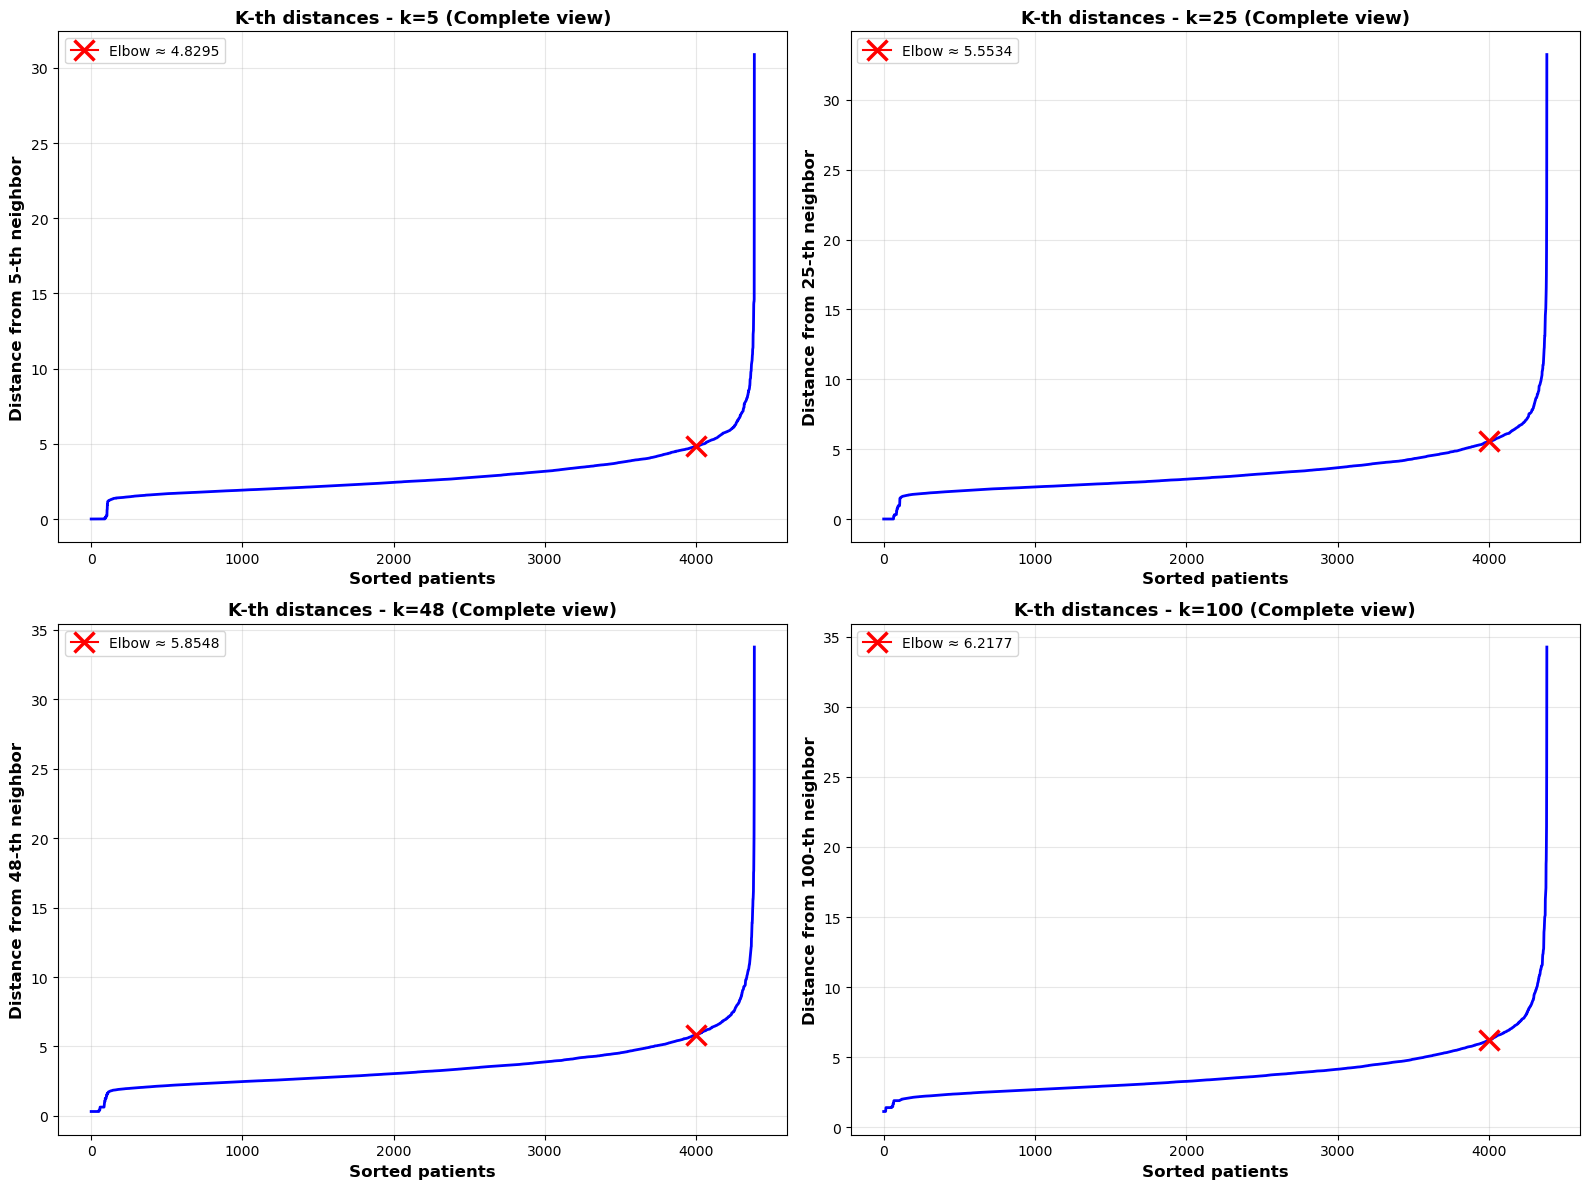


EPS ANALYSIS FOR DIFFERENT K VALUES (with Silhouette Score)
k= 5 -> EPS ≈ 4.8295 | Clusters: 1 | Noise: 260 | Silhouette: 0.4658
k=25 -> EPS ≈ 5.5534 | Clusters: 1 | Noise: 170 | Silhouette: 0.5137
k=48 -> EPS ≈ 5.8548 | Clusters: 1 | Noise: 141 | Silhouette: 0.5344
k=100 -> EPS ≈ 6.2177 | Clusters: 1 | Noise: 122 | Silhouette: 0.5502


In [9]:

# Graphical Method to Estimate EPS - Interactive Approach
# Calculate k-th distances for different k values
k_values = [5, 25, 48,100]
sorted_dists = {}

for k in k_values:
    sorted_dists[k] = getSortedList(k, dist)

# Visualize graphs for different k values
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, k in enumerate(k_values):
    sorted_k = sorted_dists[k]
    
    # Complete graph
    axes[idx].plot(range(0, len(sorted_k)), sorted_k, linewidth=2, color='blue')
    axes[idx].set_ylabel(f'Distance from {k}-th neighbor', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Sorted patients', fontsize=12, fontweight='bold')
    axes[idx].set_title(f'K-th distances - k={k} (Complete view)', fontsize=13, fontweight='bold')
    axes[idx].grid(True, alpha=0.3)
    
    # Highlight the elbow at element 4000
    gomito_idx = 4000
    axes[idx].plot(gomito_idx, sorted_k[gomito_idx], marker="x", c="red", ms=15, mew=2.5, label=f'Elbow ≈ {sorted_k[gomito_idx]:.4f}')
    axes[idx].legend(fontsize=10)

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("EPS ANALYSIS FOR DIFFERENT K VALUES (with Silhouette Score)")
print("="*60)
for k in k_values:
    gomito_idx = 4000
    eps_suggerito = sorted_dists[k][gomito_idx]
    
    # Calculate DBSCAN with suggested parameters
    dbscan_test = DBSCAN(eps=eps_suggerito, min_samples=k)
    labels_test = dbscan_test.fit_predict(X)
    
    # Count clusters and noise
    unique_labels = set(labels_test)
    n_clusters_tot = len(unique_labels)
    n_noise = list(labels_test).count(-1) if -1 in labels_test else 0
    n_clusters = n_clusters_tot - (1 if -1 in labels_test else 0)
    
    # Calculate silhouette if there are at least 2 unique labels total
    if n_clusters_tot >= 2 and n_noise < len(labels_test):
        silhouette = silhouette_score(X, labels_test)
        print(f"k={k:2d} -> EPS ≈ {eps_suggerito:.4f} | Clusters: {n_clusters} | Noise: {n_noise} | Silhouette: {silhouette:.4f}")
    else:
        print(f"k={k:2d} -> EPS ≈ {eps_suggerito:.4f} | Clusters: {n_clusters} | Noise: {n_noise} | Silhouette: N/A (all noise or 1 cluster)")


While very large values of min_samples were explored for robustness, min_samples = 48 was retained as a reference value, as it aligns with common heuristic recommendations based on the dimensionality of the feature space.

(min_points=48) -> EPS = 5.854781430886453


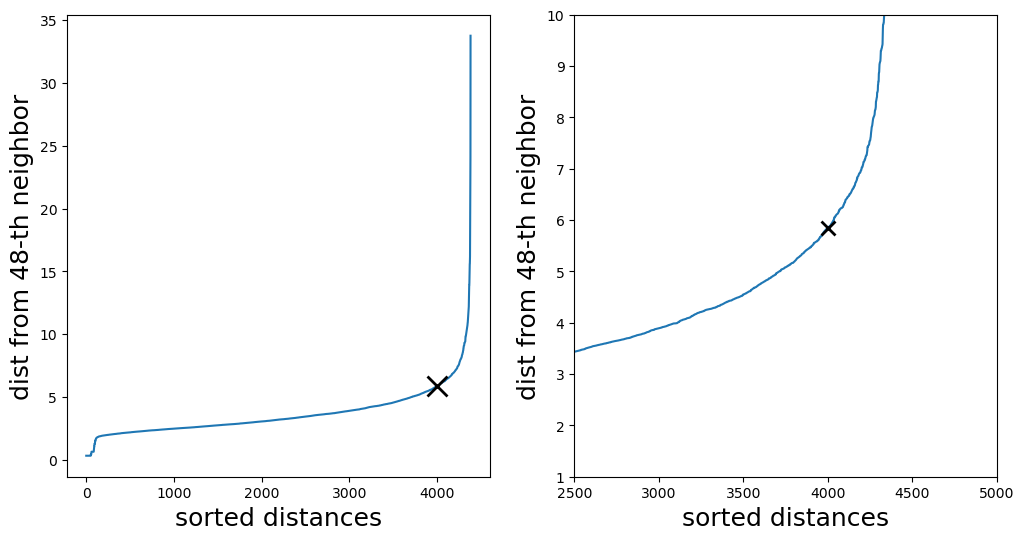

In [10]:
# Find the best eps value
fig,(ax,ax2)= plt.subplots(ncols=2,nrows=1,figsize=(12,6))

ax.plot(range(0, len(sorted_48)), sorted_48)
ax.set_ylabel('dist from 48-th neighbor', fontsize=18)
ax.set_xlabel('sorted distances', fontsize=18)
ax.plot(4000,sorted_48[4000],marker="x",c="black",ms=15,mew=2)

ax2.plot(range(0, len(sorted_48)), sorted_48)
ax2.set_ylabel('dist from 48-th neighbor', fontsize=18)
ax2.set_xlabel('sorted distances', fontsize=18)
ax2.set_ylim(1,10)
ax2.set_xlim(2500,5000)
ax2.plot(4000,sorted_48[4000],marker="x",c="black",ms=10,mew=2)

print("(min_points=48) -> EPS = "+ str(sorted_48[4000]))

### Step 2: with the eps found with the elbow method we search a value of min sample with a higher silhoutte 

In [11]:
def print_score(epsList, min_samples_):
    for eps in epsList:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples_)
        dbscan.fit(X)
        np.unique(dbscan.labels_, return_counts=True)
        clusters=len(np.unique(dbscan.labels_))
        
        print('minsample = %s, eps= %s => K= %s, Silhouette %s, Davies-Bouldin %s' %(min_samples_,eps,clusters,silhouette_score(X, dbscan.labels_), davies_bouldin_score(X, dbscan.labels_)))

eps1 = sorted_48[4000]
epsList= [eps1]

for i in range(5,151,5):
    print_score(epsList,i)

minsample = 5, eps= 5.854781430886453 => K= 2, Silhouette 0.566481080987143, Davies-Bouldin 2.0048105510961727
minsample = 10, eps= 5.854781430886453 => K= 2, Silhouette 0.5552853775427538, Davies-Bouldin 2.0309214167719167
minsample = 15, eps= 5.854781430886453 => K= 2, Silhouette 0.5492842096712846, Davies-Bouldin 2.040952036568918
minsample = 20, eps= 5.854781430886453 => K= 2, Silhouette 0.5434540805284186, Davies-Bouldin 2.05420751159099
minsample = 25, eps= 5.854781430886453 => K= 2, Silhouette 0.5409665657344594, Davies-Bouldin 2.045675956150015
minsample = 30, eps= 5.854781430886453 => K= 2, Silhouette 0.5376697927239752, Davies-Bouldin 2.0524277943197333
minsample = 35, eps= 5.854781430886453 => K= 2, Silhouette 0.5376697927239752, Davies-Bouldin 2.0524277943197333
minsample = 40, eps= 5.854781430886453 => K= 2, Silhouette 0.5351975634057355, Davies-Bouldin 2.085182315408397
minsample = 45, eps= 5.854781430886453 => K= 2, Silhouette 0.5344096295035616, Davies-Bouldin 2.0870608

A sensitivity analysis was conducted by varying the min_samples parameter from 5 to 150 while keeping the neighborhood radius ε fixed, as determined from the k-distance plot (k = 48). Across the entire range of tested values, DBSCAN consistently identified a single dense cluster accompanied by a limited number of noise points, indicating a highly stable density structure. Internal validation indices, including the Silhouette score, remained relatively stable (≈0.53), reflecting the absence of fragmentation into multiple density-based clusters. As min_samples increased, the gradual reassignment of peripheral observations to noise suggested a smooth decay of density rather than the emergence of distinct subgroups. Based on these observations, min_samples = 48 was retained as a reference value, as it aligns with dimensionality-based heuristics and preserves the observed structural stability under increasingly stringent density constraints.

### step 3 : Found the best min sample we have done a more precisely research of eps

In [12]:

from sklearn.metrics import davies_bouldin_score


for eps_ in np.arange(1,6,0.1):    
    dbscan = DBSCAN(eps=eps_, min_samples=48)
    dbscan.fit(X)
    np.unique(dbscan.labels_, return_counts=True)
    clusters=len(np.unique(dbscan.labels_))
    print('minsample = %s, eps= %s => K= %s, Silhouette %s, Davies-Bouldin %s' %(48,eps_,clusters,silhouette_score(X, dbscan.labels_), davies_bouldin_score(X, dbscan.labels_)))

minsample = 48, eps= 1.0 => K= 2, Silhouette 0.05684963093929589, Davies-Bouldin 0.9136914090833358
minsample = 48, eps= 1.1 => K= 2, Silhouette 0.05684963093929589, Davies-Bouldin 0.9136914090833358
minsample = 48, eps= 1.2000000000000002 => K= 2, Silhouette 0.05843002173266986, Davies-Bouldin 0.9171715898543189
minsample = 48, eps= 1.3000000000000003 => K= 2, Silhouette 0.05843002173266986, Davies-Bouldin 0.9171715898543189
minsample = 48, eps= 1.4000000000000004 => K= 2, Silhouette 0.05835813641903162, Davies-Bouldin 0.9237658423682862
minsample = 48, eps= 1.5000000000000004 => K= 2, Silhouette 0.05835813641903162, Davies-Bouldin 0.9237658423682862
minsample = 48, eps= 1.6000000000000005 => K= 2, Silhouette 0.05835813641903162, Davies-Bouldin 0.9237658423682862
minsample = 48, eps= 1.7000000000000006 => K= 3, Silhouette -0.16107027984195327, Davies-Bouldin 1.8499777172125098
minsample = 48, eps= 1.8000000000000007 => K= 3, Silhouette -0.14045238335593793, Davies-Bouldin 2.0384087084

Varying ε while keeping min_samples = 48 did not reveal stable multi-cluster solutions. For small ε values, DBSCAN produced fragmented and unstable clusters with low or negative Silhouette scores. As ε increased, these fragments progressively merged into a single dominant cluster accompanied by noise, with internal indices stabilizing at higher ε values. This behavior indicates a continuous density structure rather than the presence of multiple well-separated density-based clusters

the final choice is: min sample = 48 eps=5.9 

In [13]:
best_eps=5.9
best_ms=48
dbscan = DBSCAN(eps= best_eps,min_samples= best_ms)
dbscan.fit(X)

,eps,5.9
,min_samples,48
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


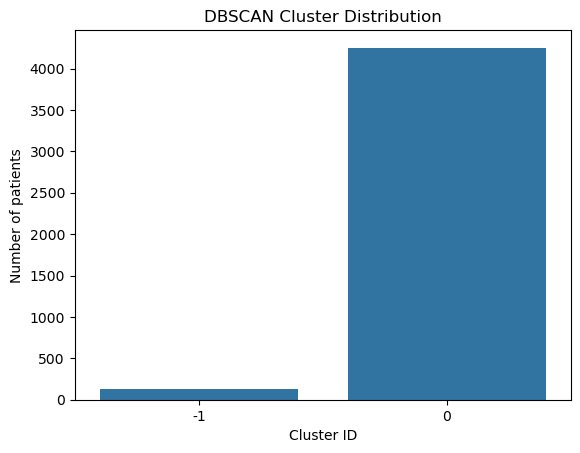

In [14]:
# Add assigned clusters to DataFrame
profile_df['cluster'] = dbscan.labels_

# Now create the plot
sns.countplot(x='cluster', data=profile_df)
plt.title("DBSCAN Cluster Distribution")
plt.xlabel("Cluster ID")
plt.ylabel("Number of patients")
plt.show()

# In-Depth Cluster Analysis

Analyze the clusters created with DBSCAN to understand the characteristics of different patient groups.

In [15]:
# 1. General cluster statistics
print("=" * 60)
print("GENERAL CLUSTER STATISTICS")
print("=" * 60)

# Count patients per cluster
cluster_counts = profile_df['cluster'].value_counts().sort_index()
print(f"\nTotal number of patients: {len(profile_df)}")
print(f"Number of clusters: {len(cluster_counts)-1}")
print("\nPatient distribution per cluster:")
for cluster_id, count in cluster_counts.items():
    percentage = (count / len(profile_df)) * 100
    cluster_name = "Noise" if cluster_id == -1 else f"Cluster {cluster_id}"
    print(f"  {cluster_name}: {count} patients ({percentage:.2f}%)")



GENERAL CLUSTER STATISTICS

Total number of patients: 4384
Number of clusters: 1

Patient distribution per cluster:
  Noise: 133 patients (3.03%)
  Cluster 0: 4251 patients (96.97%)


The DBScan analysis identified a cohesive group comprising the majority of the cohort , representing the standard clinical profile, and Atypical Profiles

In [16]:
# Percentage of each disease in each cluster
disease_cols = ['ACS_acute_ischemic','Chronic_ischemic','Heart_failure','Valvular_nonrheumatic','Myocarditis_or_cardiomyopathy','Pericardial_disease','Endocarditis','Cardiac_arrest','Arrhythmias_or_conduction']
disease_summary = profile_df.groupby('cluster')[disease_cols].mean() * 100  
disease_summary

,ACS_acute_ischemic,Chronic_ischemic,Heart_failure,Valvular_nonrheumatic,Myocarditis_or_cardiomyopathy,Pericardial_disease,Endocarditis,Cardiac_arrest,Arrhythmias_or_conduction
cluster,,,,,,,,,
-1,48.872180,7.518797,41.353383,5.263158,0.751880,2.255639,0.000000,0.000000,9.774436
0,32.110092,14.584804,29.169607,6.139732,1.129146,5.339920,0.893907,0.047048,15.149377


## Advanced Cluster Visualizations

Create more detailed graphs to better distinguish cluster+noise

### 1. Boxplot - Key Features Comparison Between Clusters

Boxplots show the complete distribution (median, quartiles, outliers) of each feature per cluster.

C:\Users\Cominotti\AppData\Local\Temp\ipykernel_18424\150394063.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_18424\150394063.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_18424\150394063.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], pa

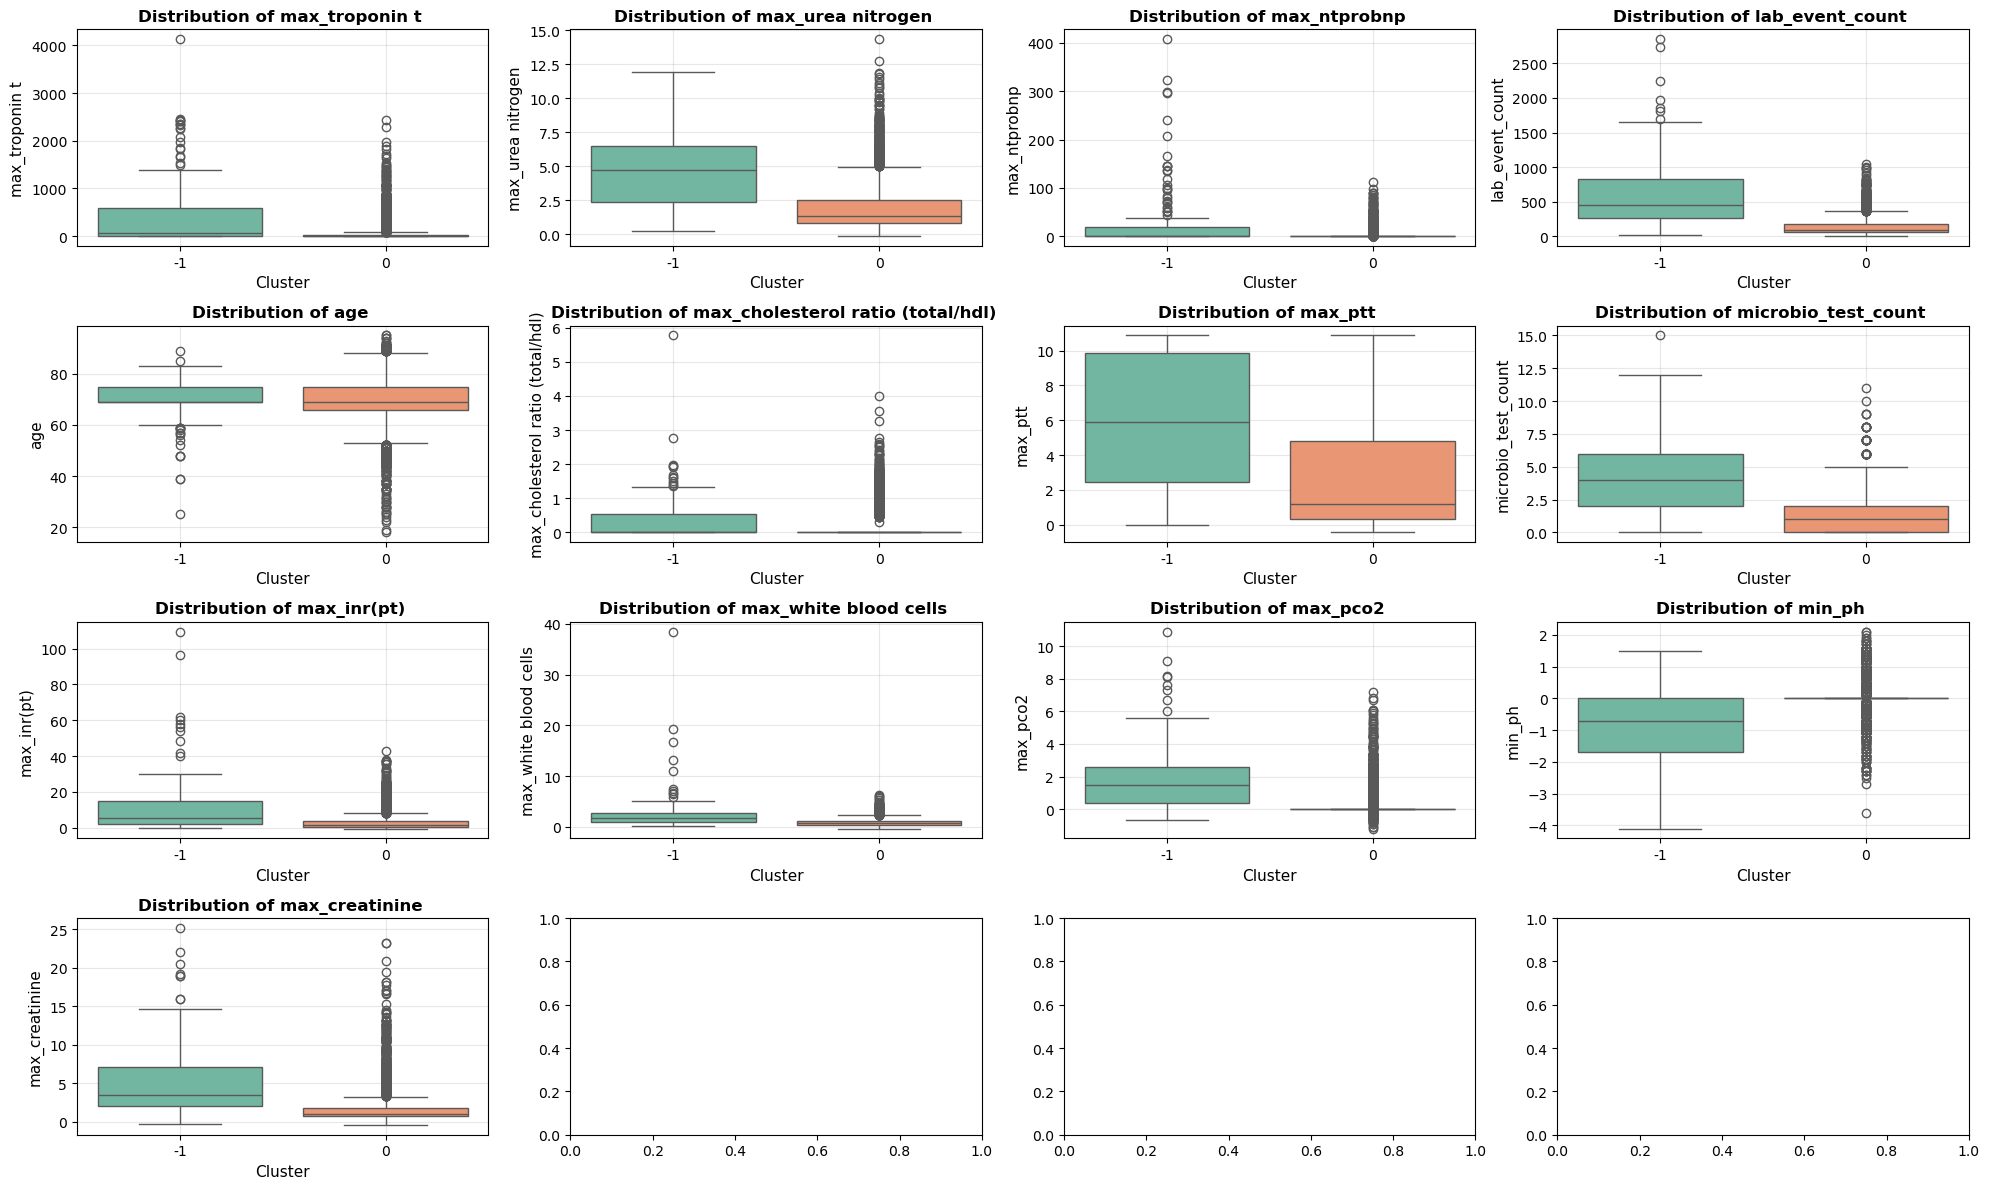

In [17]:
# Select key features to visualize
key_features = ['max_troponin t','max_urea nitrogen','max_ntprobnp', 'lab_event_count', 'age','max_cholesterol ratio (total/hdl)',
                'max_ptt','microbio_test_count','max_inr(pt)','max_white blood cells','max_pco2','min_ph','max_creatinine']

fig, axes = plt.subplots(4, 4, figsize=(20, 12))
axes = axes.flatten()

for idx, feature in enumerate(key_features):
    sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'Distribution of {feature} ', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Cluster', fontsize=11)
    axes[idx].set_ylabel(feature, fontsize=11)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

C:\Users\Cominotti\AppData\Local\Temp\ipykernel_18424\1459523080.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_18424\1459523080.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
C:\Users\Cominotti\AppData\Local\Temp\ipykernel_18424\1459523080.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx],

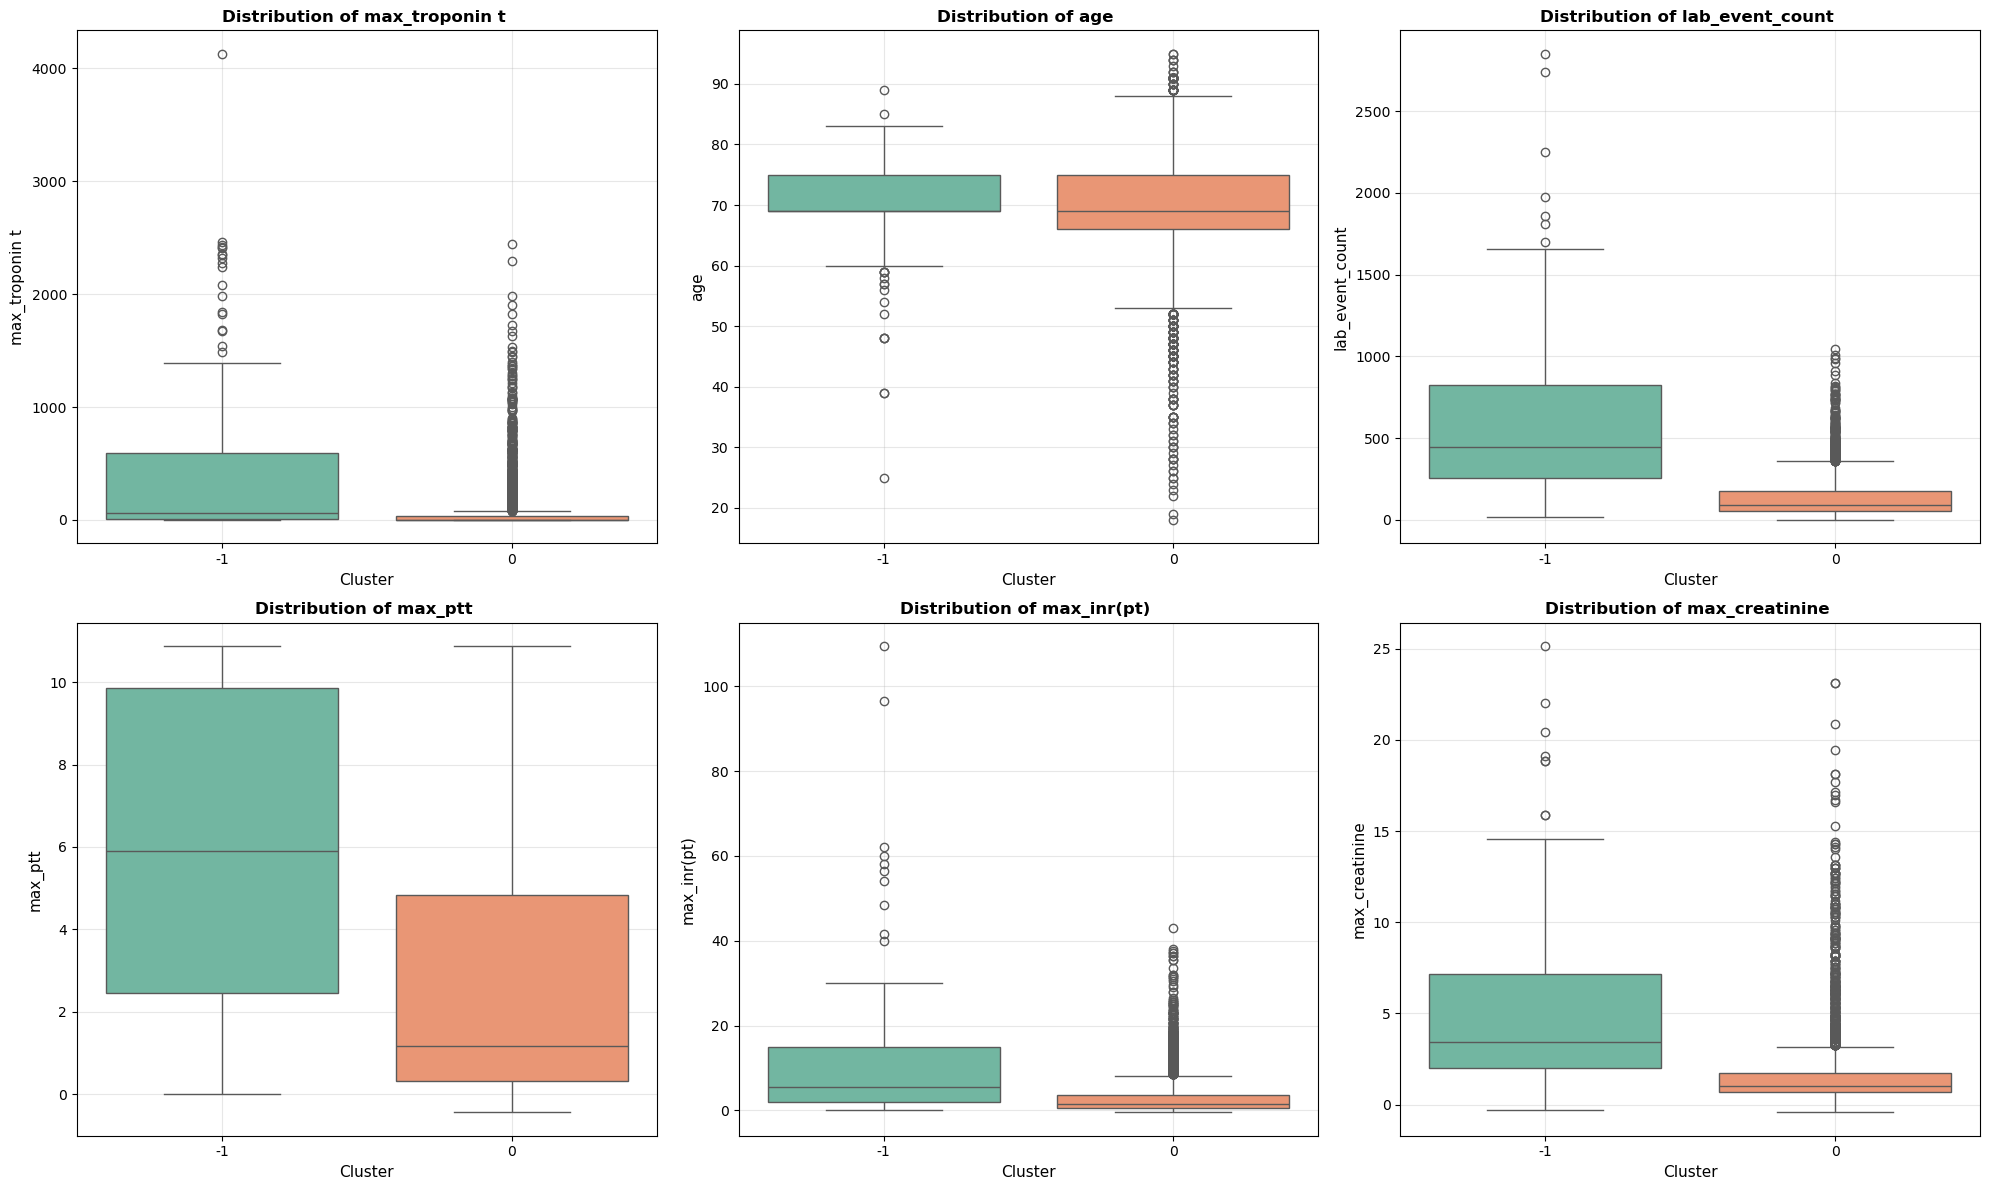

In [18]:
# Select key features to visualize
key_features = ['max_troponin t','age', 'lab_event_count', 
                'max_ptt','max_inr(pt)','max_creatinine']

fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for idx, feature in enumerate(key_features):
    sns.boxplot(data=profile_df, x='cluster', y=feature, ax=axes[idx], palette='Set2')
    axes[idx].set_title(f'Distribution of {feature} ', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Cluster', fontsize=11)
    axes[idx].set_ylabel(feature, fontsize=11)
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The boxplots display the distributions of selected key clinical variables for DBSCAN core points and peripheral observations. Peripheral observations are not interpreted as a distinct subgroup but rather as extreme cases within a continuous population. In this context, the boxplots primarily highlight increased dispersion and the presence of extreme values among peripheral points, rather than systematic differences between groups. In particular, peripheral cases exhibit higher monitoring intensity, elevated cardiac biomarkers, and more pronounced alterations in acid–base balance and coagulation parameters, consistent with severe and heterogeneous clinical presentations. In contrast, age distributions largely overlap, indicating that peripheral status is driven by clinical complexity rather than demographic factors.

### 2. Scatter Plot - Cluster Separation by Feature Pairs


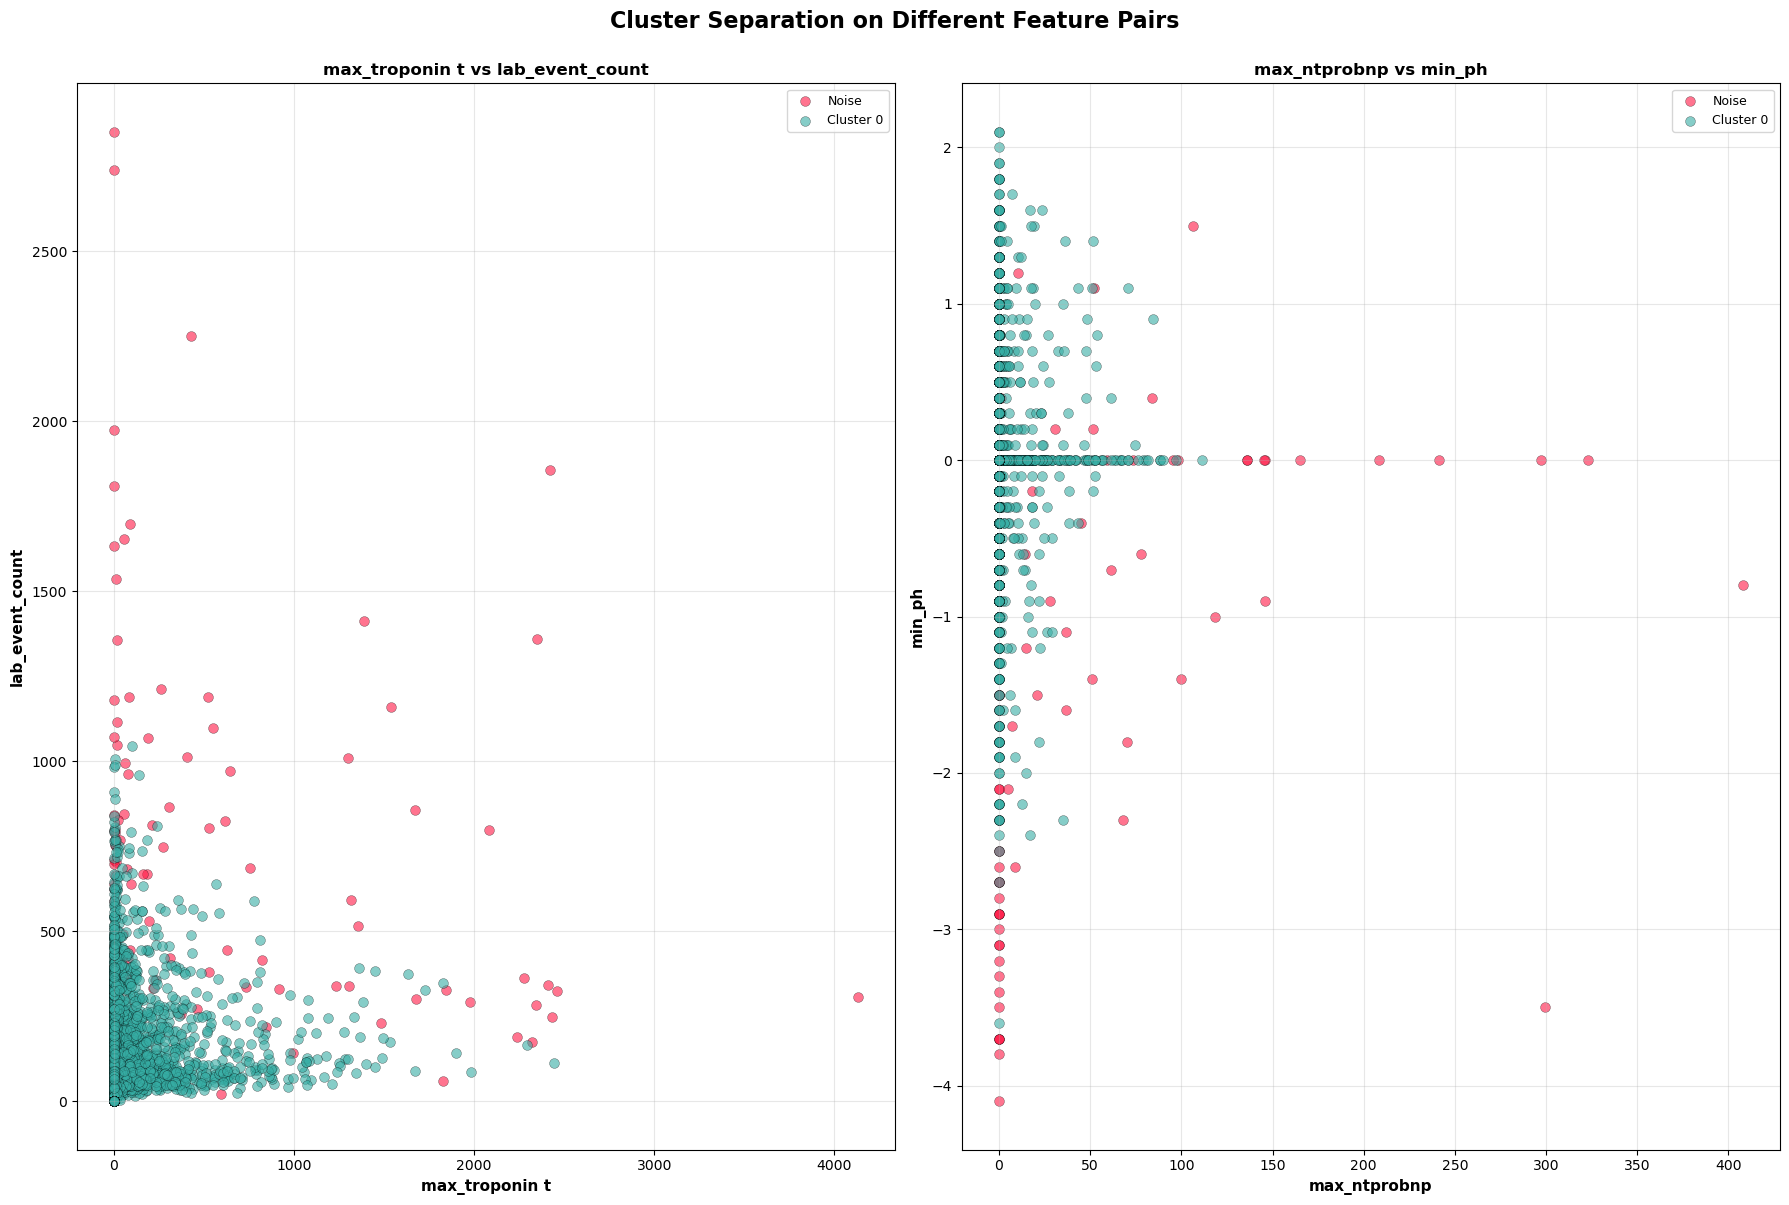

In [19]:
# Scatter plot with different feature combinations
fig, axes = plt.subplots(1,2 , figsize=(18, 12))
axes = axes.flatten()

# Define feature pairs to visualize
feature_pairs = [

    ('max_troponin t', 'lab_event_count'),
    ('max_ntprobnp', 'min_ph'),
    
]

# Color map for all clusters - beautiful and diversified palette
unique_clusters = sorted(profile_df['cluster'].unique())
palette = sns.color_palette("husl", n_colors=len(unique_clusters))
colors_map = {
    cluster_id: '#FF1744' if cluster_id == -1 else palette[idx % len(palette)]
    for idx, cluster_id in enumerate(unique_clusters)
}

for idx, (feat_x, feat_y) in enumerate(feature_pairs):
    for cluster_id in unique_clusters:
        cluster_data = profile_df[profile_df['cluster'] == cluster_id]
        label = 'Noise' if cluster_id == -1 else f'Cluster {cluster_id}'
        color = colors_map.get(cluster_id, 'gray')
        
        axes[idx].scatter(
            cluster_data[feat_x],
            cluster_data[feat_y],
            label=label,
            alpha=0.6,
            s=50,
            color=color,
            edgecolors='k',
            linewidth=0.3
        )
    
    axes[idx].set_xlabel(feat_x, fontsize=11, fontweight='bold')
    axes[idx].set_ylabel(feat_y, fontsize=11, fontweight='bold')
    axes[idx].set_title(f'{feat_x} vs {feat_y}', fontsize=12, fontweight='bold')
    axes[idx].legend(fontsize=9, loc='best')
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Cluster Separation on Different Feature Pairs', fontsize=16, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

Scattered noise points indicate atypical patients who do not conform to the predominant clinical patterns observed in the cohort.

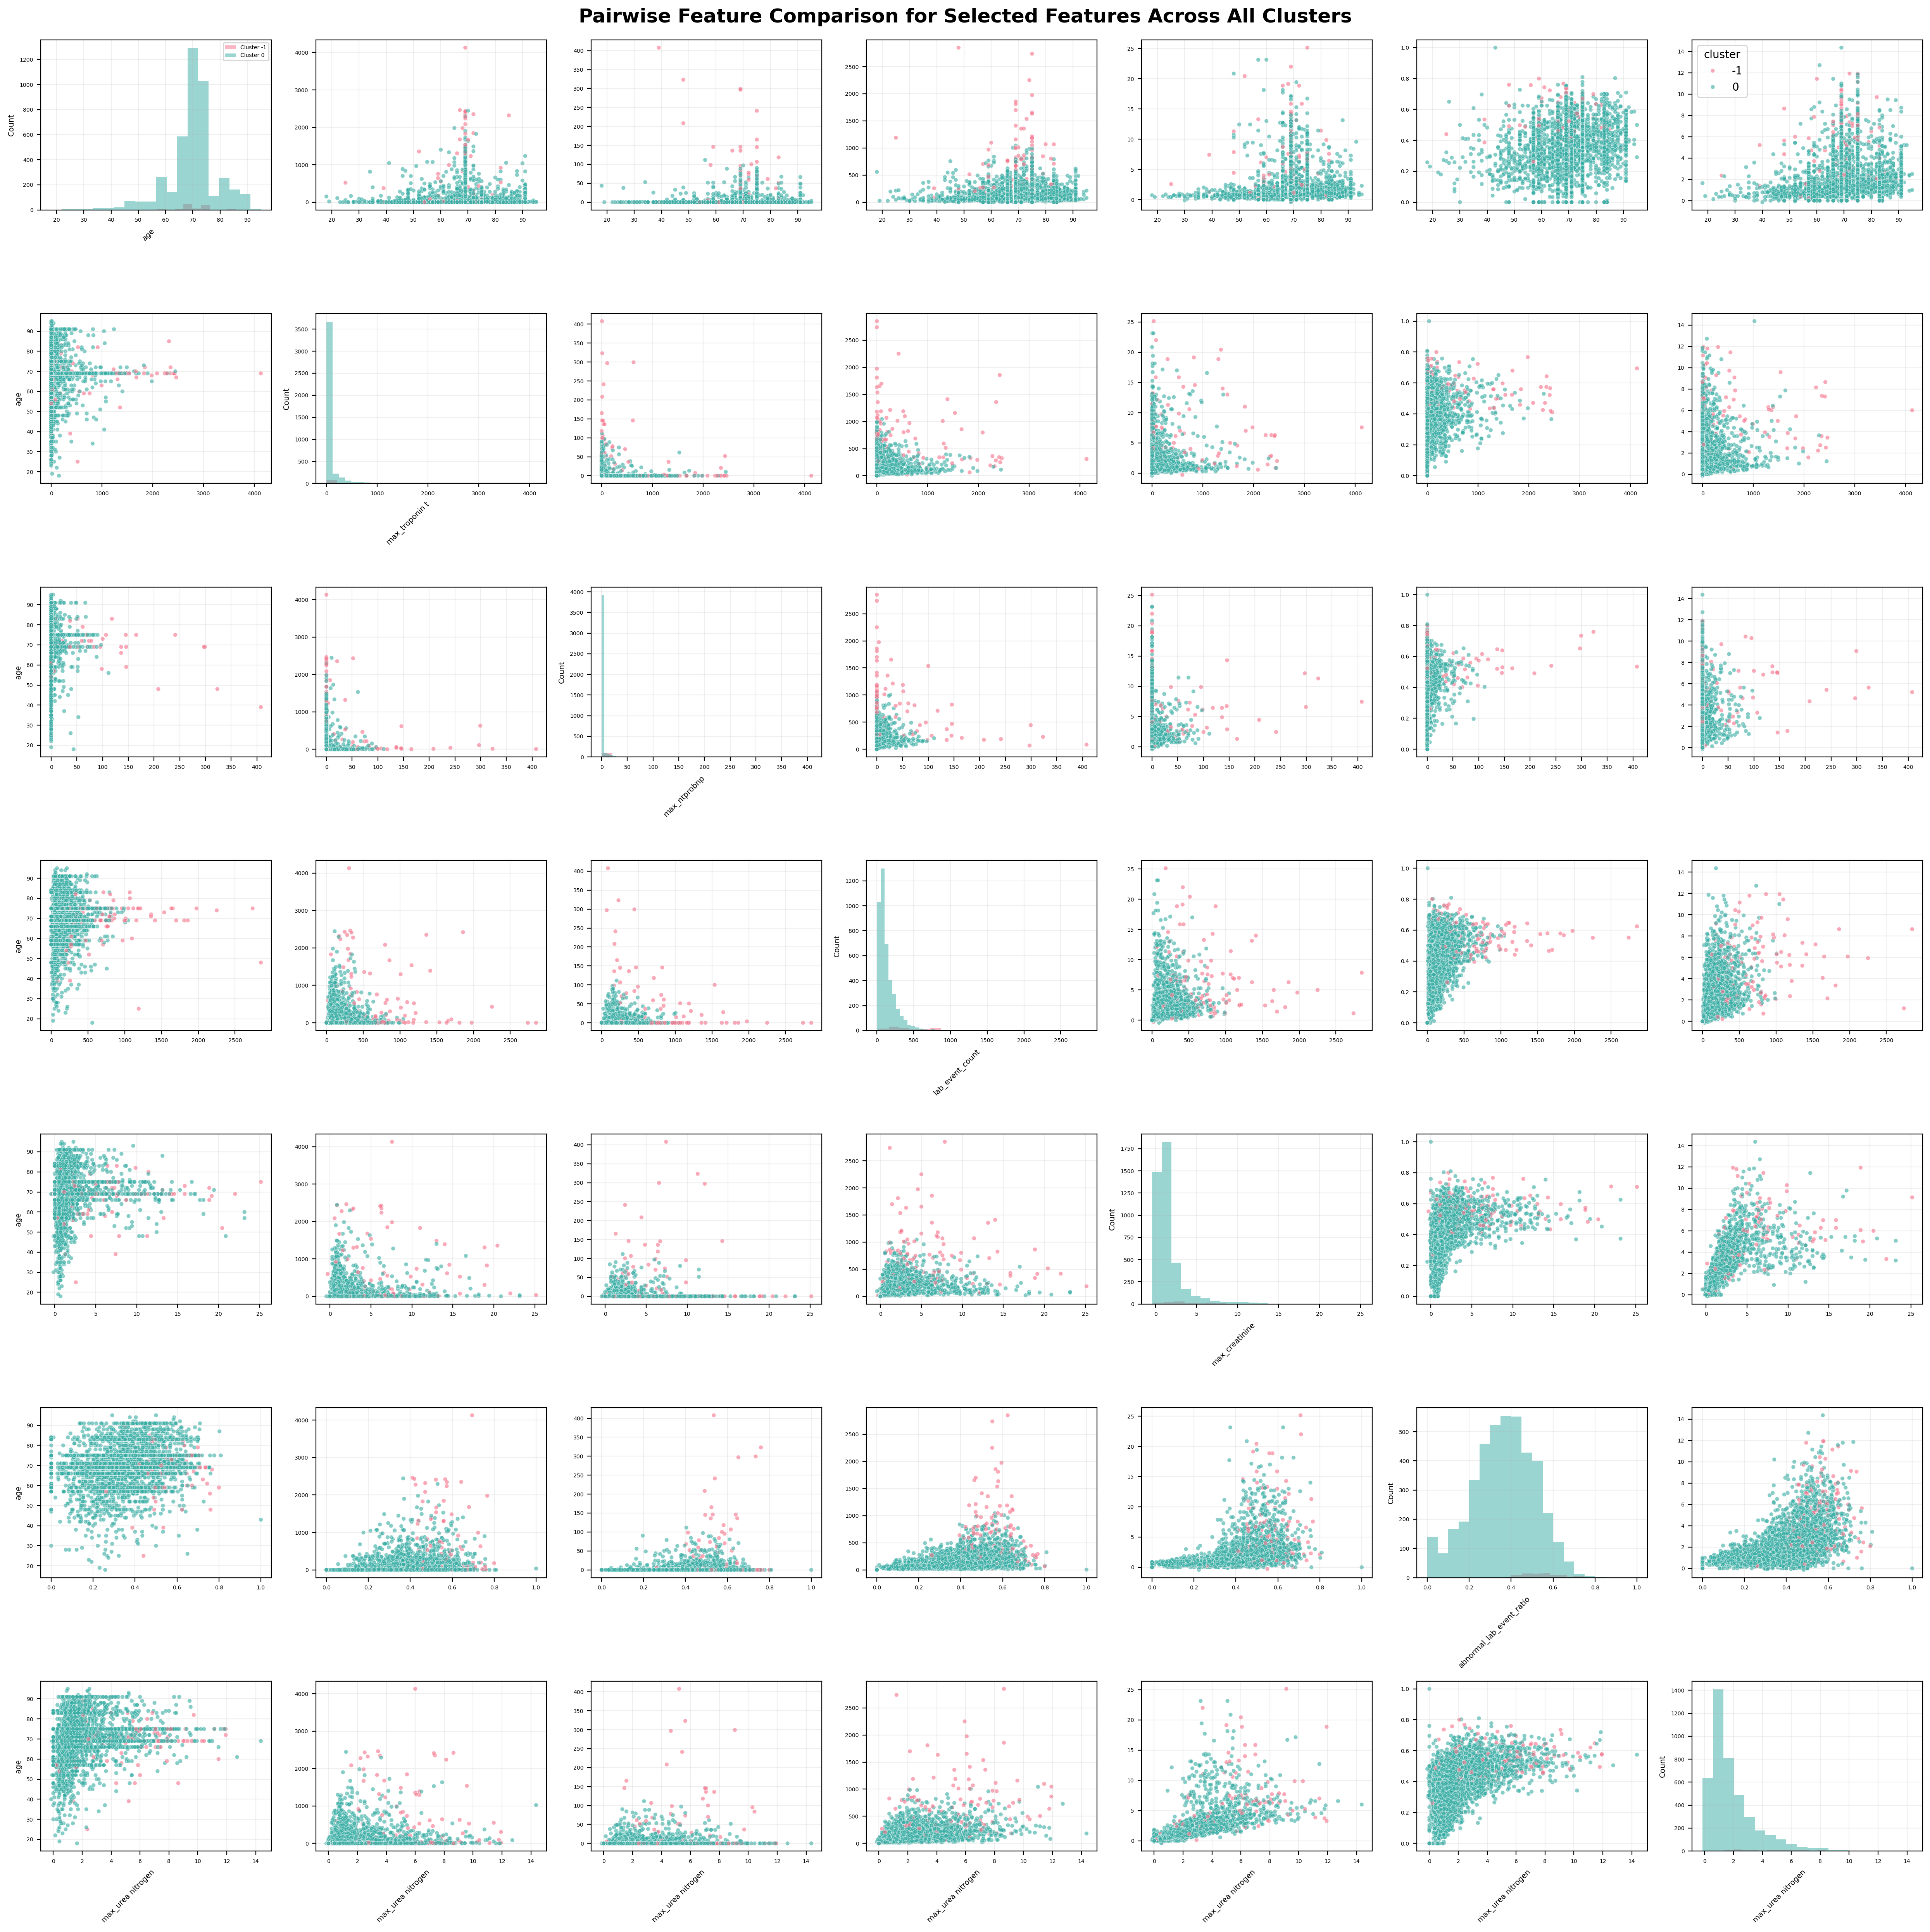

In [20]:
# Select specific feature pairs to visualize
selected_features = [
    'age', 'max_troponin t', 'max_ntprobnp', 'lab_event_count', 
    'max_creatinine', 'abnormal_lab_event_ratio', 'max_urea nitrogen'
]

n = len(selected_features)
lab = profile_df['cluster']

fig, axs = plt.subplots(n, n, figsize=(25, 25), dpi=200)

# Color map for clusters
unique_clusters = sorted(profile_df['cluster'].unique())
palette_grid = sns.color_palette("husl", n_colors=len(unique_clusters))
colors_map_grid = {cluster_id: palette_grid[idx] for idx, cluster_id in enumerate(unique_clusters)}

for i in np.arange(0, n):
    x_feature = selected_features[i]
    for j in np.arange(0, n):
        y_feature = selected_features[j]
        
        if i == j:
            # On the diagonal, show the distribution of the single feature
            for cluster_id in unique_clusters:
                cluster_data = profile_df[profile_df['cluster'] == cluster_id]
                axs[i, j].hist(cluster_data[x_feature], alpha=0.5, 
                              label=f'Cluster {cluster_id}',
                              color=colors_map_grid[cluster_id], bins=20)
            axs[i, j].set_xlabel(x_feature, fontsize=7, rotation=45, ha='right')
            axs[i, j].set_ylabel('Count', fontsize=7)
            if i == 0:
                axs[i, j].legend(fontsize=5, loc='upper right')
        else:
            # Off the diagonal, show scatter plot
            sns.scatterplot(x=x_feature, y=y_feature, data=profile_df, 
                          hue='cluster', ax=axs[i, j], alpha=0.6, s=15,
                          palette=colors_map_grid, legend=(i == 0 and j == n-1))
            axs[i, j].set_xlabel(x_feature if i == n-1 else '', fontsize=7, rotation=45, ha='right')
            axs[i, j].set_ylabel(y_feature if j == 0 else '', fontsize=7)
        
        axs[i, j].tick_params(labelsize=5)
        axs[i, j].grid(True, alpha=0.2)

plt.suptitle('Pairwise Feature Comparison for Selected Features Across All Clusters', 
             fontsize=18, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

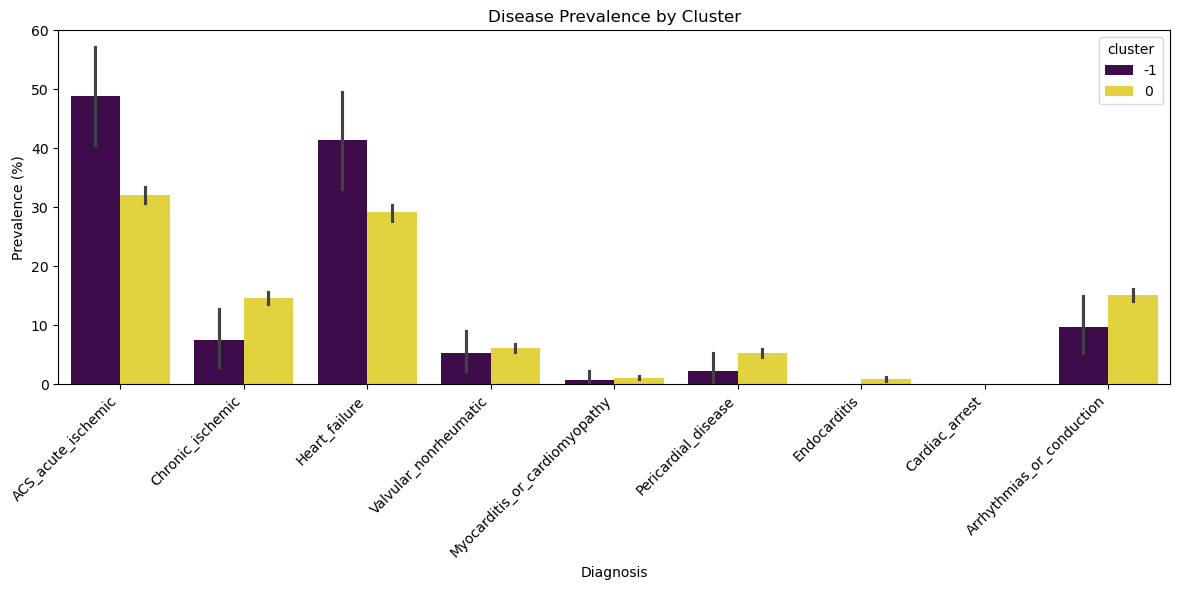

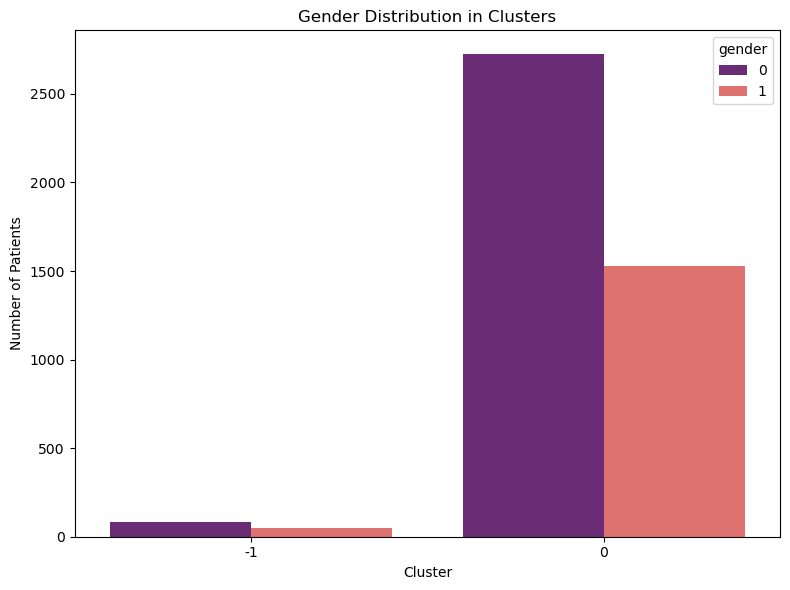

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Diagnosis graph with angled labels
diag_cols = [
    'ACS_acute_ischemic', 'Chronic_ischemic', 'Heart_failure', 'Valvular_nonrheumatic',
    'Myocarditis_or_cardiomyopathy', 'Pericardial_disease', 'Endocarditis',
    'Cardiac_arrest', 'Arrhythmias_or_conduction'
]

# Data preparation
df_melted = profile_df.melt(id_vars=['cluster'], value_vars=diag_cols)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_melted, 
    x='variable', 
    y='value', 
    hue='cluster', 
    estimator=lambda x: sum(x)/len(x)*100,
    palette='viridis'
)

plt.ylabel('Prevalence (%)')
plt.xlabel('Diagnosis')
plt.title('Disease Prevalence by Cluster')


plt.xticks(rotation=45, ha='right') 


plt.tight_layout()  

plt.show()

# 2. Gender distribution graph
plt.figure(figsize=(8, 6))
sns.countplot(data=profile_df, x='cluster', hue='gender', palette='magma')
plt.title('Gender Distribution in Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Patients')
plt.tight_layout()

plt.show()

Diagnosis prevalence plots show that peripheral observations identified by DBSCAN are associated with a higher prevalence of acute ischemic syndromes and heart failure, consistent with more severe clinical presentations. However, these cases are not interpreted as a distinct clinical cluster, but rather as extreme manifestations within a continuous patient population. Gender distributions are comparable between core and peripheral observations, indicating that peripheral status is driven by clinical complexity rather than demographic differences.
